# 04 · Conditioning, CFG and classifier guidance

Use an exactly known class posterior to understand guidance before assessing learned classifiers or text encoders.

**Prerequisites:** 01–03; Bayes' rule and gradients of log probabilities.

**By the end:** Verify the conditional-score identity; compare CG/CFG; inspect null-label training and branch costs; interpret guidance strength and classifier calibration.

Run from top to bottom. Default experiments use CPU, fixed seeds and no downloads. Small trained models illustrate learning; analytic oracles isolate mathematical and solver effects. Neither is an image-quality benchmark.

[Course index](README.md) · [Notation](../docs/23_notation_and_code.md) · [Implementation scope](../docs/15_coverage_and_scope.md)

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import Image, display

project = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "diffusion_lab").is_dir())
if str(project) not in sys.path:
    sys.path.insert(0, str(project))
torch.set_num_threads(2)
torch.manual_seed(7)
np.random.seed(7)
plt.rcParams.update(
    {
        "figure.figsize": (10, 3.6),
        "axes.spines.top": False,
        "axes.spines.right": False,
        "figure.dpi": 100,
    }
)
ENABLE_WIDGETS = False  # Set True in Jupyter; static figures work on GitHub.
print(f"PyTorch {torch.__version__}; CPU lesson; seed=7; no automatic downloads.")


def scatter(ax, samples, title, labels=None, limits=(-4.5, 4.5)):
    points = samples.detach().cpu().numpy()
    colors = labels.detach().cpu().numpy() if labels is not None else "steelblue"
    ax.scatter(
        points[:, 0],
        points[:, 1],
        c=colors,
        cmap="tab10" if labels is not None else None,
        s=5,
        alpha=0.55,
        linewidths=0,
    )
    ax.set(title=title, xlabel="$x_1$", ylabel="$x_2$", aspect="equal", xlim=limits, ylim=limits)


def saved_gallery(relative, caption):
    path = project / relative
    if not path.is_file():
        raise FileNotFoundError(f"Missing curated course evidence: {relative}")
    print(caption)
    display(Image(filename=str(path)))


def animate_particles(history, name, title, labels=None, limits=(-4.5, 4.5)):
    from matplotlib.animation import FuncAnimation, PillowWriter

    points = history.detach().cpu().numpy()
    indices = np.linspace(0, len(points) - 1, min(32, len(points))).astype(int)
    fig, ax = plt.subplots(figsize=(4.5, 4.5))
    colors = labels.detach().cpu().numpy() if labels is not None else "steelblue"
    dots = ax.scatter(
        *points[0].T,
        c=colors,
        cmap="tab10" if labels is not None else None,
        s=9,
        alpha=0.65,
        linewidths=0,
    )
    ax.set(xlim=limits, ylim=limits, aspect="equal", xlabel="$x_1$", ylabel="$x_2$")

    def update(frame):
        dots.set_offsets(points[indices[frame]])
        ax.set_title(f"{title}: frame {frame + 1}/{len(indices)}")
        return (dots,)

    animation = FuncAnimation(fig, update, frames=len(indices), interval=100)
    folder = project / "assets/teaching/notebooks"
    folder.mkdir(parents=True, exist_ok=True)
    target = folder / f"{name}.gif"
    animation.save(target, writer=PillowWriter(fps=10), dpi=75)
    plt.close(fig)
    display(Image(filename=str(target)))

PyTorch 2.7.1+cu128; CPU lesson; seed=7; no automatic downloads.


## 1. Bayes connects a classifier to a score

$$\nabla_x\log p_t(x|y)=s_t(x)+\nabla_x\log p_t(y|x).$$
Classifier guidance (CG) uses $s_{\rm CG}=s_u+w\nabla\log p_\phi(y|x,t)$.
A classifier trained only on clean images need not estimate a noisy posterior.
Classifier-free guidance (CFG) mixes $s_u+w(s_c-s_u)$, or mixes equivalent
linear prediction coordinates at a fixed time.
Here $w=0$ is null, $w=1$ ordinary conditioning, $w>1$ extrapolation.
Some papers/libraries instead write $(1+w)s_c-ws_u$; always check conventions.
**Code:** `classifier_gradient`, `classifier_free`, `AnalyticGMMClassifier` in [guidance.py](../diffusion_lab/guidance.py).

In [2]:
from diffusion_lab.data import GaussianMixture
from diffusion_lab.guidance import (
    AnalyticGMMClassifier,
    classifier_free,
    classifier_gradient,
    drop_labels,
)
from diffusion_lab.paths import GaussianPath, expand
from diffusion_lab.solvers import integrate

mixture, path = GaussianMixture(), GaussianPath()
classifier = AnalyticGMMClassifier(mixture, path)
x = torch.randn(96, 2)
t = torch.full((len(x),), 0.3)
labels = torch.arange(len(x)) % mixture.components
a, s = path.coefficients(t)
unconditional = mixture.score(x, a, s)
conditional = mixture.score(x, a, s, labels)
gradient = classifier_gradient(classifier, x, t, labels)
torch.testing.assert_close(unconditional + gradient, conditional, atol=2e-5, rtol=2e-5)
print("Bayes conditional-score identity verified against a noisy-posterior oracle.")

Bayes conditional-score identity verified against a noisy-posterior oracle.


## 2. Learn a null branch through condition dropout

A class-conditioned model has `K+1` label embeddings; index `K` is null.
Randomly replacing labels teaches unconditional and conditional fields in one
network. `labels=None` selects the null embedding at inference.
Dropping every label prevents learning class-specific behavior; dropping none
leaves the null branch unsupervised.
**Code:** `Conditioning` in [models.py](../diffusion_lab/models.py), `drop_labels` in [guidance.py](../diffusion_lab/guidance.py).

In [3]:
labels = torch.arange(10000) % 8
dropped = drop_labels(labels, 8, 0.15, torch.Generator().manual_seed(51))
print("Observed null-label fraction:", (dropped == 8).float().mean().item())
assert set(dropped.unique().tolist()) == set(range(9))

Observed null-label fraction: 0.1559000015258789


## 3. Hold initial noise fixed while changing guidance

The exact GMM score below isolates the mechanism. Use the actual finite-time
unconditional marginal at $t=.999$. Its small difference from a conditional
initial marginal is disclosed; strong guidance also changes the intended law.
The plot does not assess a trained noisy classifier.

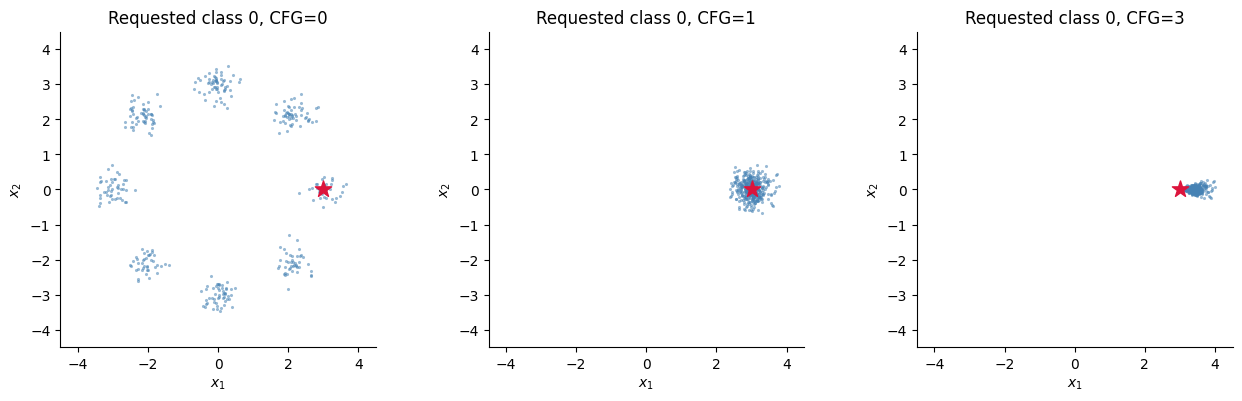

0.0 distance to requested mean: 3.924220323562622
1.0 distance to requested mean: 0.31908079981803894
3.0 distance to requested mean: 0.43250572681427


In [4]:
class ExactScore(torch.nn.Module):
    def forward(self, x, t, labels=None):
        return mixture.score(x, *path.coefficients(t), labels)


g = torch.Generator().manual_seed(52)
clean, _ = mixture.sample(384, g)
a, s = path.coefficients(torch.full((len(clean),), 0.999))
initial = expand(a, clean) * clean + expand(s, clean) * torch.randn(clean.shape, generator=g)
requested = torch.zeros(len(initial), dtype=torch.long)
scales = [0.0, 1.0, 3.0]
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
generated_by_scale = {}
for ax, scale in zip(axes, scales, strict=True):

    def field(x, t, scale=scale):
        f, g = path.sde(x, t)
        guided = classifier_free(ExactScore(), x, t, requested, scale)
        return f - 0.5 * expand(g.square(), x) * guided

    generated, _ = integrate(field, initial, torch.linspace(0.999, 0.005, 251), "heun")
    generated_by_scale[scale] = generated
    scatter(ax, generated, f"Requested class 0, CFG={scale:g}")
    ax.scatter(*mixture.means[0], marker="*", s=150, c="crimson")
plt.tight_layout()
plt.show()
for scale, generated in generated_by_scale.items():
    print(
        scale,
        "distance to requested mean:",
        torch.linalg.vector_norm(generated - mixture.means[0], dim=1).mean().item(),
    )

In [5]:
# At an identical state/time, exact CG and exact CFG fields coincide.
state = torch.randn(64, 2)
time = torch.full((64,), 0.4)
requested = torch.full((64,), 2, dtype=torch.long)
for scale in [0.0, 1.0, 3.0]:
    cfg = classifier_free(ExactScore(), state, time, requested, scale)
    cg = ExactScore()(state, time) + scale * classifier_gradient(classifier, state, time, requested)
    torch.testing.assert_close(cfg, cg, atol=2e-5, rtol=2e-5)
print("CG=CFG with exact compatible fields; learned estimation errors need not match.")

CG=CFG with exact compatible fields; learned estimation errors need not match.


## 4. Count calls, not just solver steps

At $w=0$ or $1$, the implementation uses one branch. For other scales with a
condition it uses two. A Heun step with extrapolated CFG therefore uses four
denoiser branch calls. Batched branches may share one Python invocation but
still require two examples' worth of denoiser work. CG adds classifier forward/backward work.
CLIP energy on a denoised estimate is a separate heuristic, not a calibrated noisy posterior.
**Code:** [image_guidance.py](../diffusion_lab/image_guidance.py).

In [6]:
class Counter(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.calls = 0

    def forward(self, x, t, labels=None):
        self.calls += 1
        return torch.zeros_like(x)


for scale in [0.0, 1.0, 3.0]:
    counted = Counter()
    classifier_free(counted, state, time, requested, scale)
    print(f"CFG={scale:g}: {counted.calls} denoiser branch calls")

CFG=0: 1 denoiser branch calls
CFG=1: 1 denoiser branch calls
CFG=3: 2 denoiser branch calls


In [7]:
def explore_guidance(scale=1.0, class_id=0):
    labels = torch.full((len(initial),), class_id, dtype=torch.long)

    def guided_field(x, t):
        f, g = path.sde(x, t)
        score = classifier_free(ExactScore(), x, t, labels, scale)
        return f - 0.5 * expand(g.square(), x) * score

    samples, _ = integrate(guided_field, initial, torch.linspace(0.999, 0.005, 251), "heun")
    _fig, ax = plt.subplots()
    scatter(ax, samples, f"Class {class_id}, CFG={scale:g}")
    plt.show()


if ENABLE_WIDGETS:
    from ipywidgets import interact

    interact(explore_guidance, scale=(0.0, 4.0, 0.5), class_id=(0, 7))

## Exercises and worked answers

1. Can strong CFG improve prompt adherence and simultaneously hurt diversity?
2. Why must a classifier be evaluated at the same noise convention as the sampler?
3. Replace class 0 with class 4 and reuse the initial noise. Inspect the sample cloud, not only its mean.

<details><summary>Worked answers</summary>

1. Yes. It extrapolates a field and can concentrate mass, distort geometry or reduce mode coverage.
2. Otherwise its gradient estimates the wrong conditional law. EDM classifiers here receive `log(sigma)/4`; discrete diffusion uses its normalized table time.
3. Mean agreement alone can hide variance collapse and missing modes. Use held-out classification and distribution diagnostics when studying learned image models.

</details>

**Image evidence:** [Guidance chapter](../docs/04_guidance.md), [results](../docs/14_advanced_results.md).
**Continue:** [Likelihood and evaluation](05_likelihood_and_evaluation.ipynb).
**Sources:** [CG](https://arxiv.org/abs/2105.05233), [CFG](https://arxiv.org/abs/2207.12598).